# **_PRACTICA 0_**


In [ ]:
# Actualizar R ----
# library(installr)
# updateR()

# Repaso de R ----

## R como calculadora ----
2+3
5/2
pi
sqrt(4)
5^3
75^(1/3)

## Variables en R ----

a <- 14
a = 7
b <- a*2
e <- 5
d <- a+e
ls() # elementos guardados

# Ejercicio

n <- 10

max_aristas <- n*(n-1)/2
max_arcos <- n*(n-1)

# Funciones en R ----
# Nota: Ctrl+Shift+C para comentar

# Estructura general de una función:
# nombre <- function(argumentos){
#   operaciones
#   return(objeto)
# }

area_rectangulo <- function(lado1=1, lado2=1, ...){
  area <- lado1*lado2
  print(area)
  return(area)
}

area_rectangulo(2,3)
a <- area_rectangulo(lado1=2, lado2=3, 4)

## Instrucciones de control ----
# Estructura general de un condicional
# if(condicion){
#   operaciones
# }

x <- 7

# Si solo se usa una línea, no son necesarias las llaves
if(x>5) cat("x es mayor que 5")
if(x>5){
  cat("x es mayor que 5")
}else{
  cat("x no es mayor que 5")
}

ifelse(x>5, "x es mayor que 5", "x no es mayor que 5")

for(i in 1:4) print(i)
dias <- c("lunes", "martes", "miercoles", "jueves", "viernes")

for(dia in dias) print(dia)

x<-3

while(x<5){
  print(x)
  x <- x+1
}

# Ejercicio

coste_trayecto <- function(distancia, precio_km=0.35, peaje=0){
  
  coste <- distancia*precio_km + peaje
  
  if(distancia > 200){
    coste <- coste*0.9
  }
  
  return(coste)
}

coste_trayecto(150)
coste_trayecto(250, peaje=12)
coste_trayecto(300, precio_km=0.40, peaje=8)

# 17/09/2026
# Vectores ----
a <- c(1,3,5)
a[1]
a[2]
a[1:2]
a[c(1,3)]
1:3
a[-2] # todas las posiciones menos la 2
a[-c(1,3)] # todas las posiciones menos la 1 y 3

b <- c(2,4,6)
a+b
a*b
b[4] <- 8
b
a*b 
# al multiplicar vectores de distinta longitud, 
# opera con normalidad y cuando llega a los elementos extra
# va ciclando -> c(a[1]*b[1], a[2]*b[2], a[3]*b[3], a[1]*b[4])

# Funciones lógicas
a[c(T,T,F)]
a[a<5]
which(a<5)
a[which(a<5)]
max(a)
which.max(a)

x <- c(3,7,4,7,5,6)
max(x)
which.max(x) # solo saca una posición, la del primer máximo que encuentra
which(x == max(x)) # aquí sí devuelve todas las posiciones

numeric(7) # vector de 7 ceros
unique(x) # mismo vector sin valores repetidos

a
x
setdiff(a,x) # vector de elementos de a que no están en x

1:5
5:1
seq(from=1, to=5, by=0.5) # como el np.arange de python
seq(1.5, by=0.5)
seq(1.5, length.out=15)

rep(1, times=5)
rep(1:3, times=5)
rep(1:3, each=5)

# Matrices ----

A <- matrix(1:9); A # El ; es un salto de línea
# Por defecto R almacena todo por columnas
A <- matrix(1:9, nrow=3, byrow=T) # byrow=T hace que sea por filas

rbind(A, 1:3) # añade una fila
cbind(A, 1:3) # añade una columna

# Manera alternativa de crear una matriz
B <- rbind(c(1,3,5),
           c(3,2,4),
           c(4,5,6)
           )
B
B[1,3]
B[1,1:3] 
B[1,] # primera fila
B[,3] # tercera columna

nrow(B) # número de filas
ncol(B) # número de columnas
dim(B) # dimensión

t(B) # matriz transpuesta
B
diag(B) <- 1
B

all(B == t(B)) # devuelve true si es simétrica la matriz
isSymmetric(B) # también se puede usar
A
B
A+B
A*B # Esto multiplica elemento a elemento
A%*%B # Esto es la multiplicación matricial
A^2 # Potencia elemento a elemento
A%*%A # no es cómodo pero por defecto se usa esto para potencias

# Esta librería hace las potencias matriciales más cómodas
library(expm)
A%^%2
all(A%^%2 == A%*%A)

B
which(B == max(B), arr.ind=T)


# Listas ----

lista <- list(1:7, c("palabraa", "palabra"), B, c(T,F))
lista
lista[[2]][2]
lista[[3]][2,3]

# En vez de usar doble corchete, podemos darles nombres
# a los elementos de la lista y acceder a ellos con $
names(lista) <- c("A", "B", "C", "D")
lista$B
lista$C[2,3]

# También se pueden dar nombres en la definición
lista <- list(A=1:7, B= c("palabraa", "palabra"), C=B, D=c(T,F))
lista[[2]]
lista[["B"]]
lista$B


# Data frames ----

datos <- data.frame(
  Grado = c("B", "A", "B"),
  Edad = c(20, 21, 22)
)

mean(datos$Edad)
datos[,2]
datos[1,]
nrow(datos) # n datos medidos
ncol(datos) # n variables que se estudian
datos[,"Edad"]
datos[datos$Edad < 22,]


# **_PRÁCTICA 1_**


In [2]:
# PRACTICA 1 - INTRODUCCION A LA TEORIA DE GRAFOS
# Modelos de Optimizacion en Redes

# 1.1. PAQUETE igraph ----
# Ejecutar SOLO la primera vez:
# install.packages("igraph")

library(igraph)



Adjuntando el paquete: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union




## **_Introducción a grafos_**


Warning message:
“`graph()` was deprecated in igraph 2.1.0.
ℹ Please use `make_graph()` instead.”


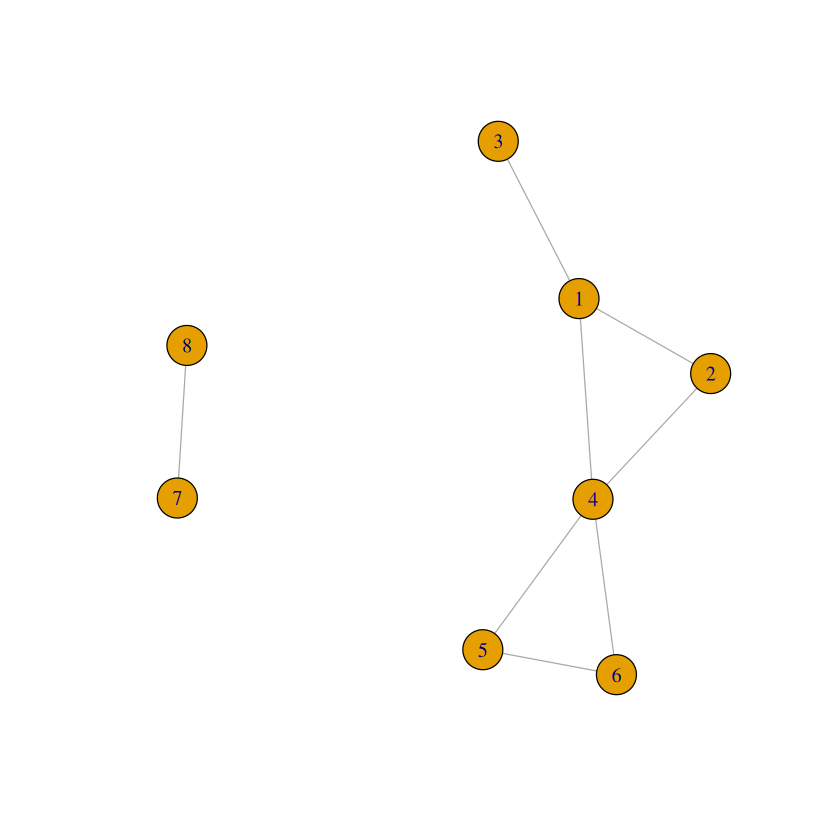

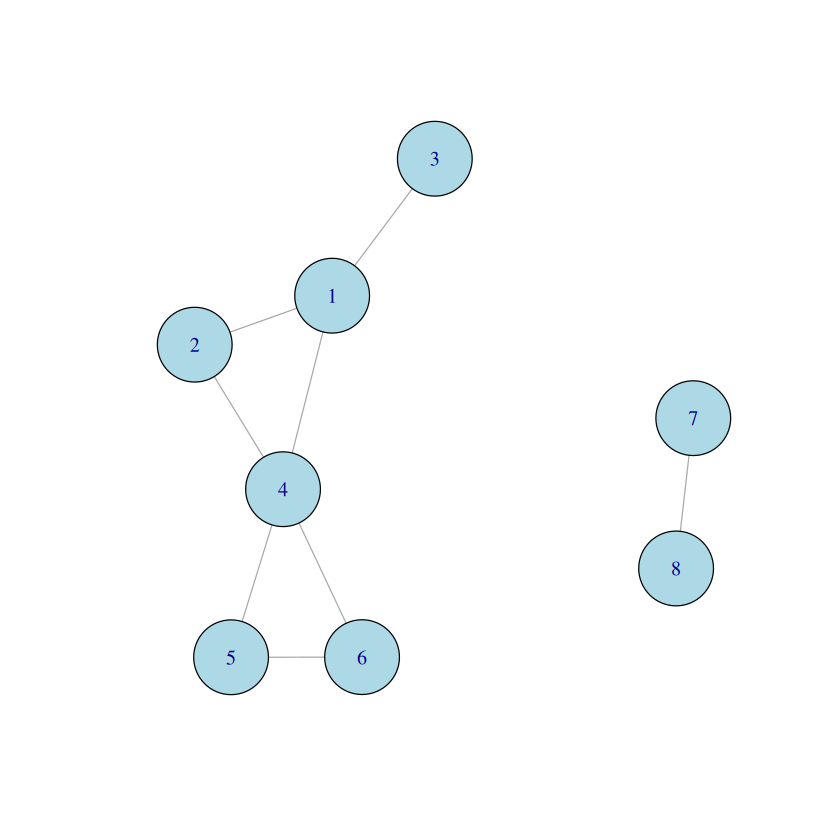

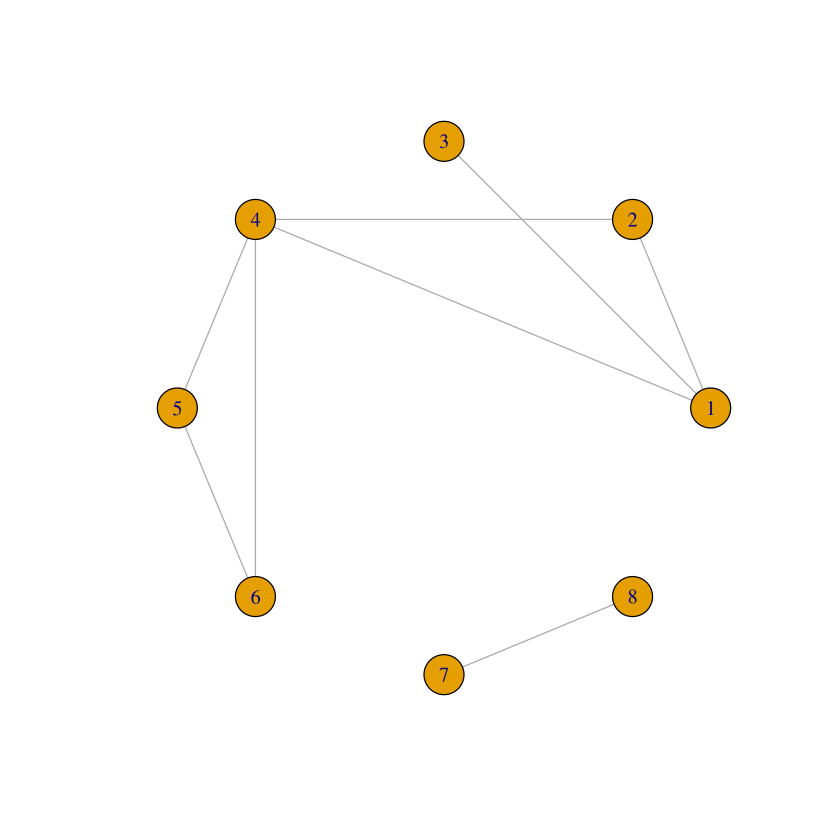

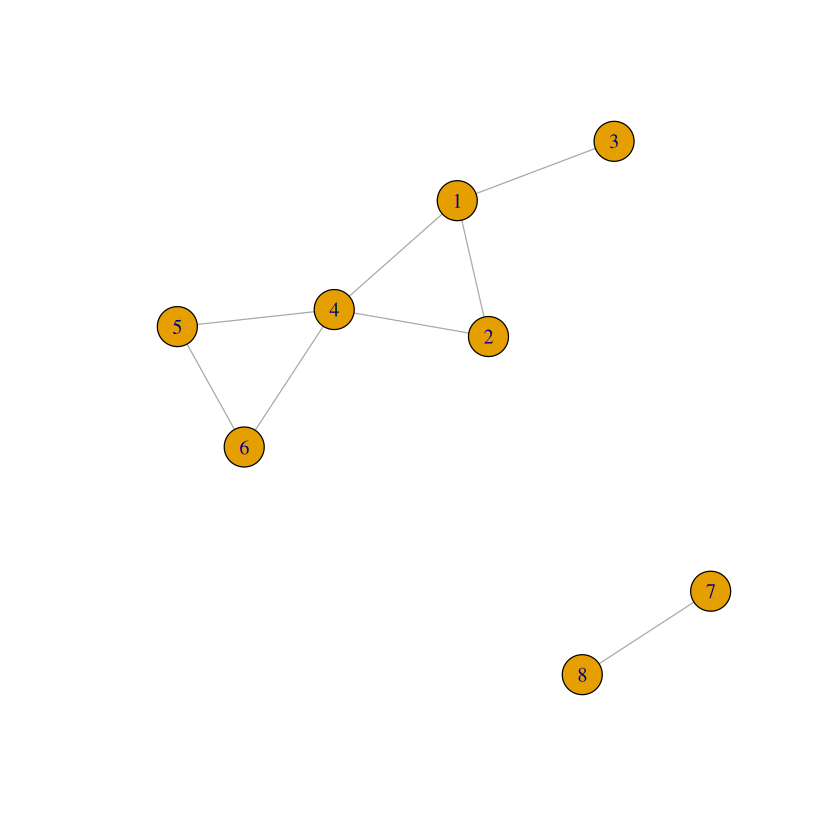

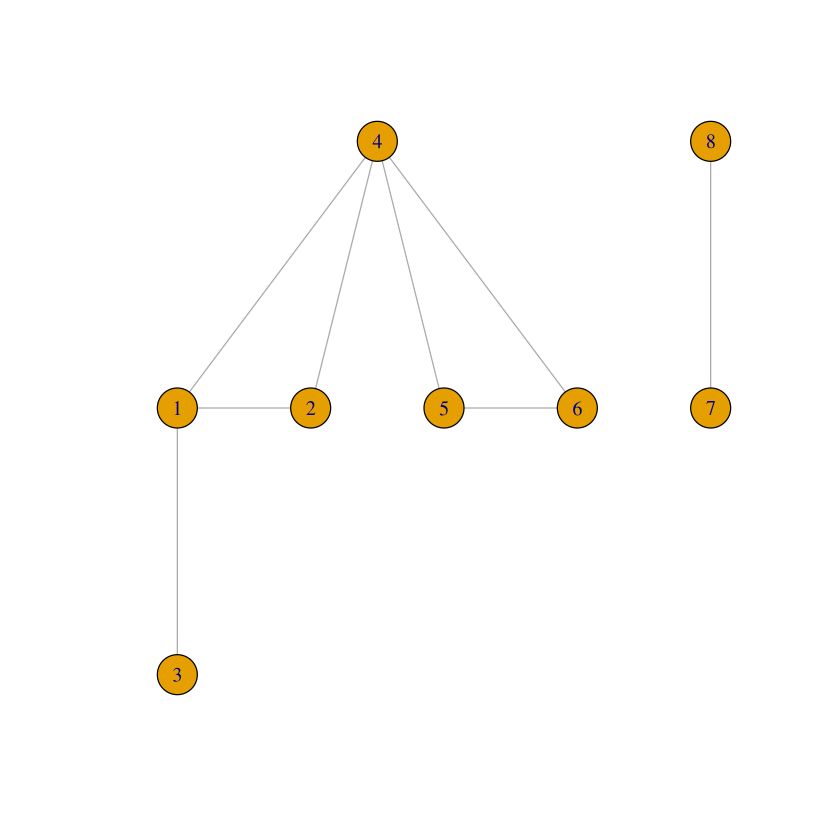

[1] FALSE

[1] TRUE

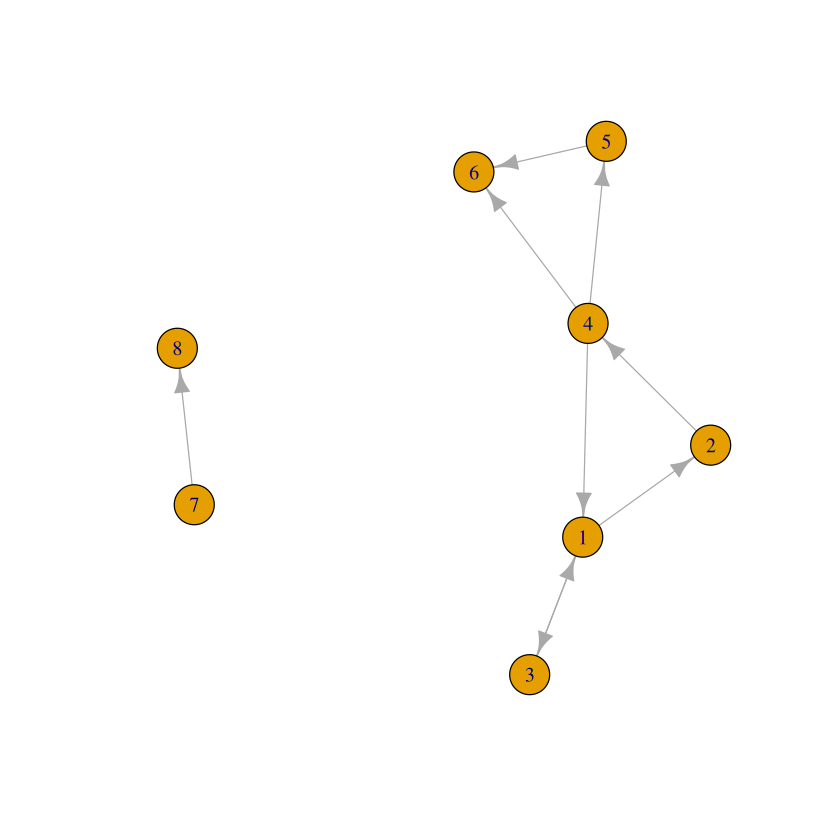

In [3]:
# 1.2. INTRODUCCION A GRAFOS ----

## 1.2.1. Primeros pasos para grafos no orientados ----
G <- graph(
  c(1,2,
    1,3,
    1,4,
    2,4,
    4,5,
    4,6,
    5,6,
    7,8),
  directed = FALSE
)

plot(G)

plot(
  G,
  layout = layout_with_fr(G),
  vertex.size = 30,
  vertex.color = "lightblue",
  vertex.label.cex = 1,
  edge.arrow.size = 0.5
)

plot(G, layout = layout_in_circle(G))
plot(G, layout = layout_with_kk(G))
plot(G, layout = layout_as_tree(G))

# 1.2.2. Primeros pasos para grafos orientados
G2 <- graph(
  c(1,3,
    3,1,
    1,2,
    2,4,
    4,1,
    4,5,
    5,6,
    4,6,
    7,8),
  directed = TRUE
)

plot(G2)

is_directed(G)
is_directed(G2)


## **_Conceptos básicos_**


[1] 8

[1] 8

[1] 8

[1] 9

[1] TRUE

[1] TRUE

[1] FALSE

[1] FALSE

[1] 3

[1] 2

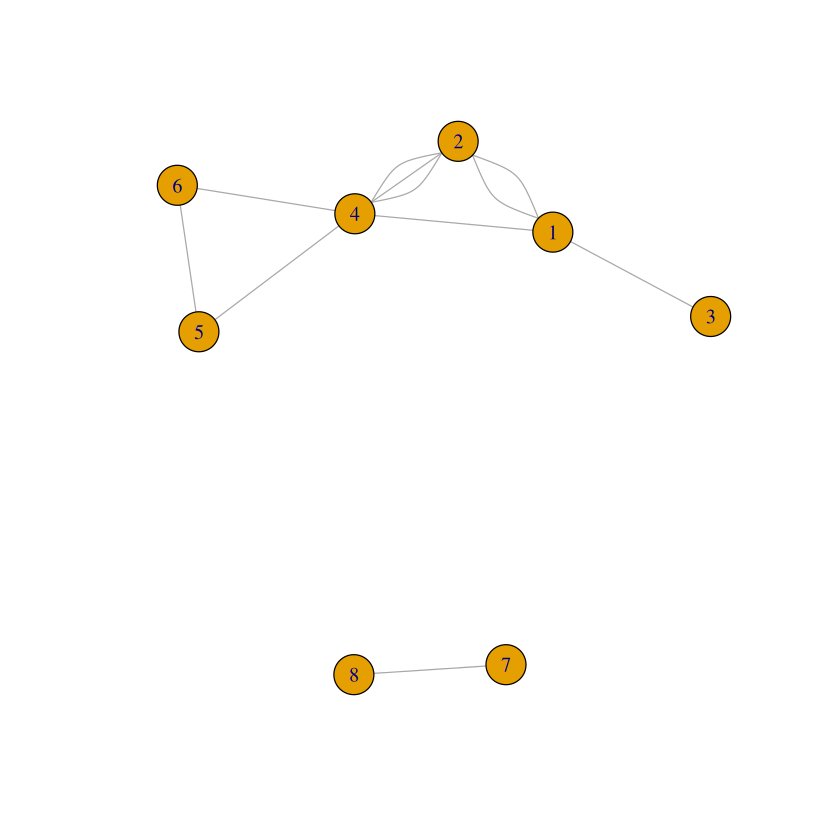

[1] FALSE

[1] FALSE

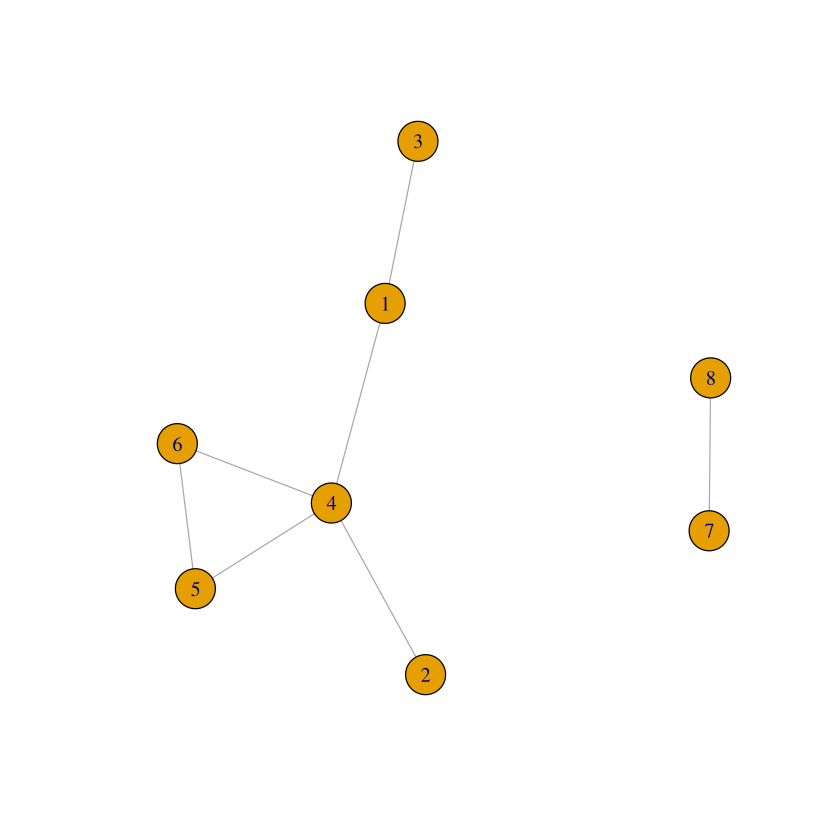

[1] TRUE

[1] 2

[1] TRUE

[1] TRUE

[1] FALSE

[1] FALSE

[1] FALSE

[1] TRUE

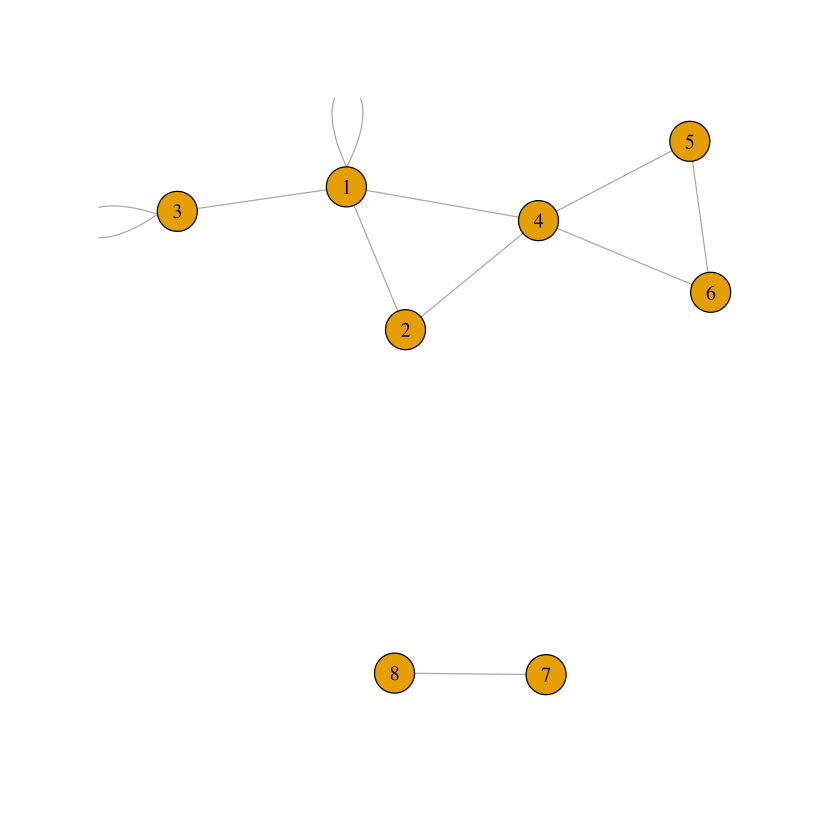

[1] FALSE

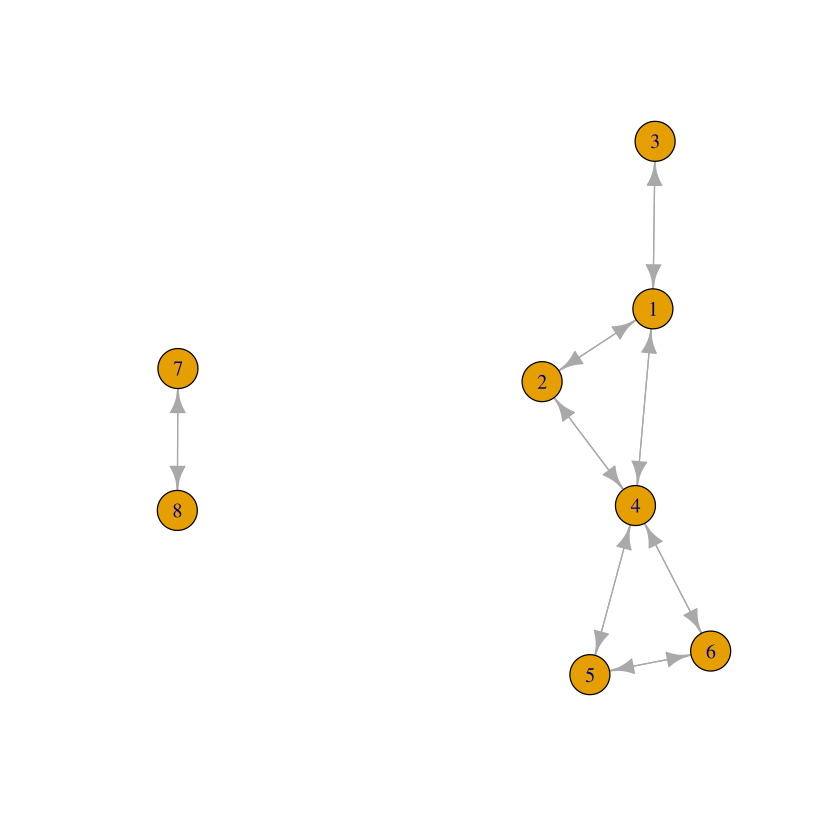

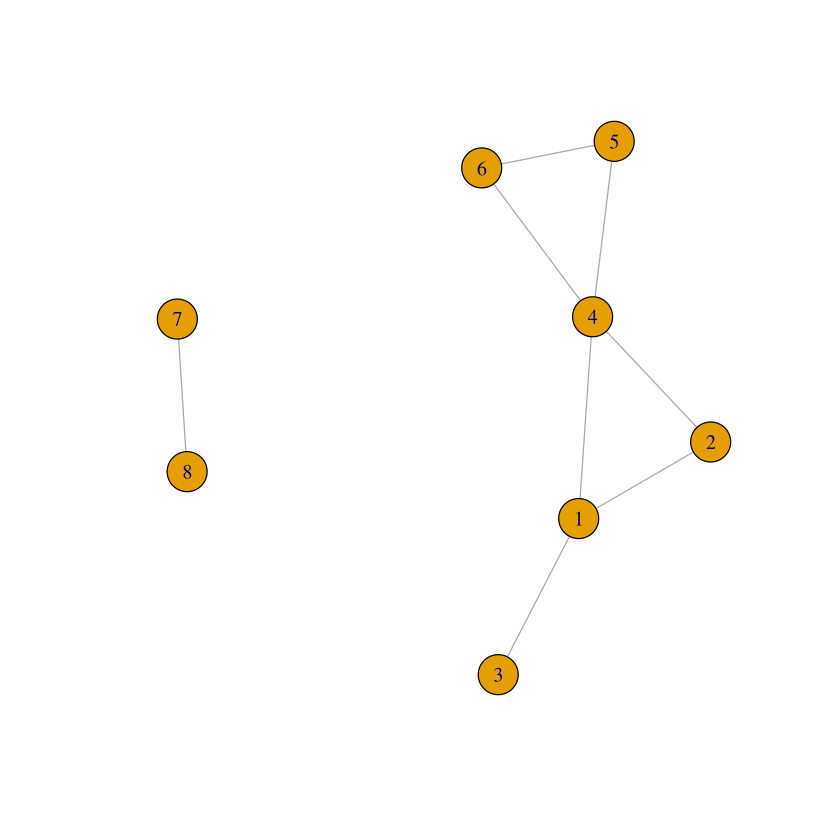

In [5]:


# 1.3. CONCEPTOS BASICOS -----


## 1.3.1. Orden y tamano ----

vcount(G)
vcount(G2)

ecount(G)
ecount(G2)

## 1.3.2. 1-grafos ----
!any_multiple(G)
!any_multiple(G2)

Gbis <- add_edges(G, c(1, 2))

G_extra <- add_edges(G, c(1, 2, 2, 4, 4, 2))
plot(G_extra)

G2_extra <- add_edges(G2, c(1, 2, 2, 4, 4, 2))

!any_multiple(G_extra)
!any_multiple(G2_extra)

max(count_multiple(G_extra))
max(count_multiple(G2_extra))

id <- get_edge_ids(G, c(1,2))
G_sin_arista <- delete_edges(G, id)
plot(G_sin_arista)

## 1.3.3. Bucles ----
any_loop(G)
any_loop(G2)

G_bucle <- add_edges(G, c(1, 1, 3, 3))
plot(G_bucle)

any_loop(G_bucle)

sum(which_loop(G_bucle))

## 1.3.4. Grafo simple----
is_simple(G)
is_simple(G2)
is_simple(G_extra)
is_simple(G2_extra)
is_simple(G_bucle)

## 1.3.5. Grafo orientado equivalente ----
G_orientado <- as_directed(G)
is_directed(G_orientado)
plot(G_orientado)

## 1.3.6. Grafo subyacente no orientado ----
G2_no_orientado <- as_undirected(G2, mode = "collapse")
is_directed(G2_no_orientado)
plot(G2_no_orientado)


## **_Grafos orientados_**


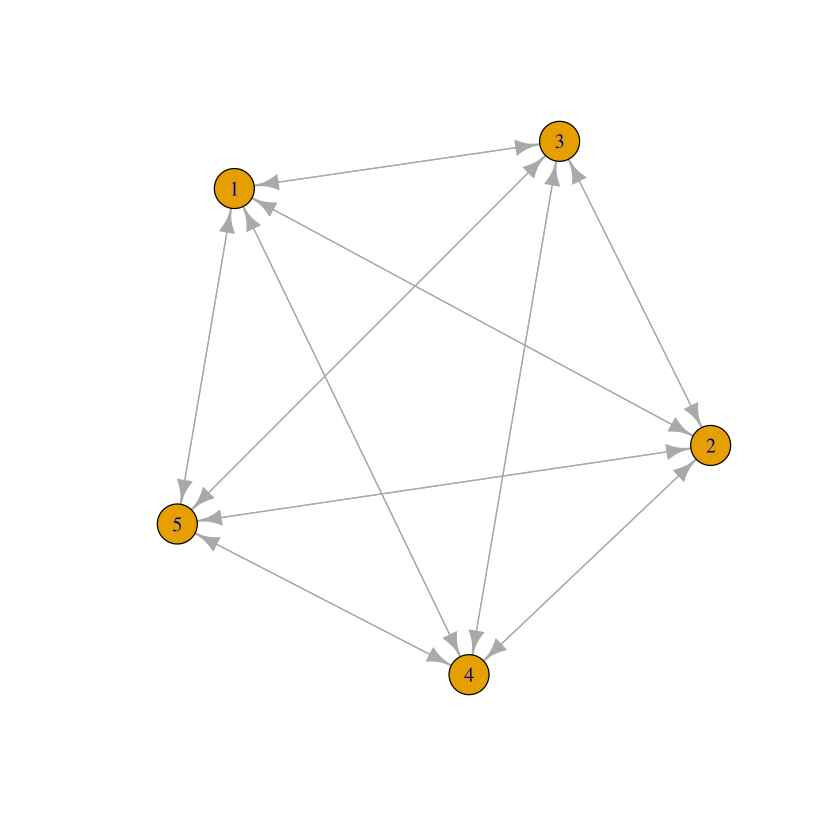

[1] 2 1 1 3 1 0 1 0

[1] 2 1 1 1 1 2 0 1

[1] 4 2 2 4 2 2 1 1

[1] 3

[1] 1

...

+ 4/8 vertices, from 9d26d92:
[1] 1 2 5 6

+ 6/8 vertices, from 9d26d92:
[1] 2 4 1 5 6 3

+ 5/8 vertices, from 9d26d92:
[1] 5 4 2 1 3

[1] 1 2 4 5 6

[1] 1 4 2

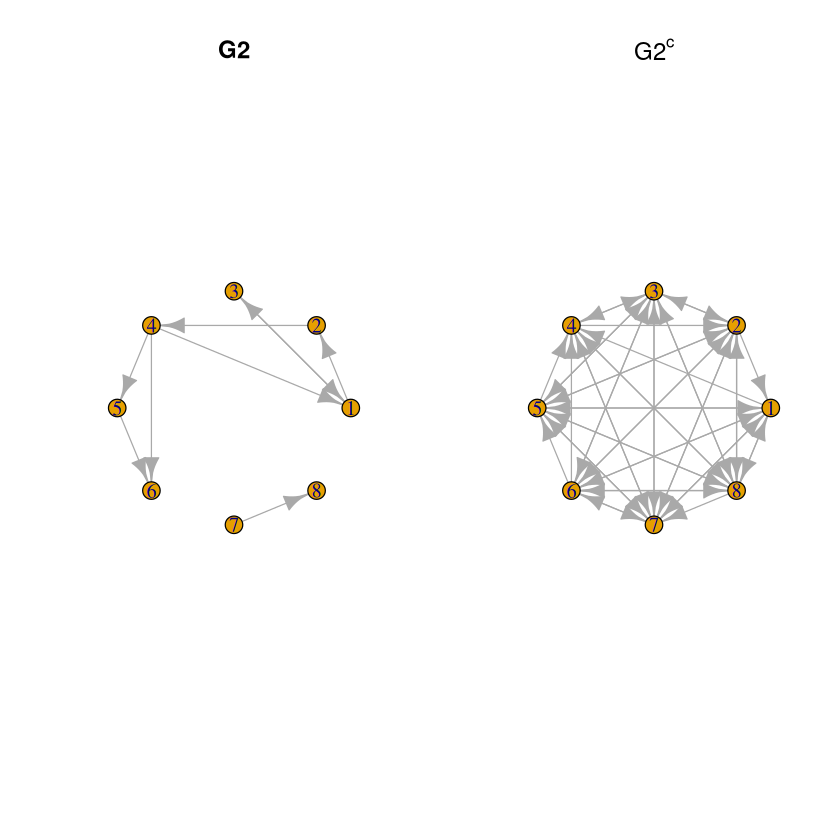

In [7]:


# 1.4. GRAFOS ORIENTADOS ----

## 1.4.1. Grafos completos ----
K5_dir <- make_full_graph(5, directed = TRUE)
plot(K5_dir)

## 1.4.2. Subgrafo generado ----
H <- induced_subgraph(G2, vids = c(1,2,3,4))
H <- induced_subgraph(G2, vids = 1:4)

## 1.4.3. Grafo parcial ---- 
ids <- get.edge.ids(G2, c(1,2, 1,3, 5,6))
H2 <- subgraph.edges(G2, ids, delete.vertices = FALSE)

## 1.4.4. Grafo complementario ----
G2c <- complementer(G2, loops = FALSE)

L <- layout_in_circle(G2)
par(mfrow = c(1,2))
plot(G2, layout = L, main = "G2")
plot(G2c, layout = L, main = expression(G2^c))
par(mfrow = c(1,1))

## 1.4.5. Grados de incidencia en un grafo orientado ----
degree(G2, mode = "out")
degree(G2, mode = "in")
degree(G2, mode = "total")

degree(G2, v = 4, mode = "out")
degree(G2, v = 4, mode = "in")
degree(G2, v = 4, mode = "total")

## 1.4.6. Sucesores y antecesores ----
neighbors(G2, 4, mode = "out")
neighbors(G2, 4, mode = "in")
neighbors(G2, 4, mode = "all")

## 1.4.7. Ascendientes y descendientes ----
subcomponent(G2, 2, mode = "out")
subcomponent(G2, 5, mode = "in")

setdiff(as_ids(subcomponent(G2, 3, mode = "out")), 3)
setdiff(as_ids(subcomponent(G2, 3, mode = "in")), 3)


## **_Grafos no orientados_**


In [6]:

# 1.5. GRAFOS NO ORIENTADOS ----

## 1.5.1. Grafos completos ----
K6 <- make_full_graph(6, directed = FALSE)

## 1.5.2. Subgrafo generado, grafo parcial y complementario ----
H3 <- induced_subgraph(G, vids = c(1,2,3,4))

ids2 <- get.edge.ids(G, c(1,2, 7,8))
H4 <- subgraph.edges(G, ids2, delete.vertices = FALSE)

Gc <- complementer(G, loops = FALSE)

## 1.5.3. Grado de incidencia en un grafo no orientado ----
degree(G)
degree(G, v = 3)


Warning message:
“`get.edge.ids()` was deprecated in igraph 2.1.0.
ℹ Please use `get_edge_ids()` instead.”
Warning message:
“`subgraph.edges()` was deprecated in igraph 2.1.0.
ℹ Please use `subgraph_from_edges()` instead.”


[1] 3 2 1 4 2 2 1 1

[1] 1

### **_Representación matricial_**


In [ ]:

# 1.6. REPRESENTACION MATRICIAL ----

A2 <- as_adjacency_matrix(G2, sparse = FALSE)
A2

A <- as_adjacency_matrix(G, sparse = FALSE)
A

## 1.6.1. Numero de caminos/cadenas de longitud fija ----
A2_4 <- A2 %*% A2 %*% A2 %*% A2
A2_4[1,3]

A_4 <- A %*% A %*% A %*% A
A_4[1,3] + A_4[3,1]

## 1.6.2. Construccion de un grafo a partir de su matriz de adyacencia ----
G2bis <- graph_from_adjacency_matrix(
  A2,
  mode = "directed"
)

plot(G2bis)

Gbis <- graph_from_adjacency_matrix(
  A,
  mode = "undirected"
)

plot(Gbis)


## **_Conexión en grafos no orientados_**


In [ ]:

# 1.7. CONEXION EN GRAFOS NO ORIENTADOS ----

is_connected(G)

components(G)
components(G)$membership
components(G)$csize
components(G)$no

comp <- components(G)

lapply(seq_len(comp$no), function(i) {
  which(comp$membership == i)
})

A3 <- matrix(
  c(
    0, 1, 1, 1, 1,
    1, 0, 0, 0, 0,
    1, 0, 0, 0, 0,
    1, 0, 0, 0, 0,
    1, 0, 0, 0, 0
  ),
  nrow = 5,
  byrow = TRUE
)

G3 <- graph_from_adjacency_matrix(A3, mode = "undirected")
is_connected(G3) && is_acyclic(G3)

bridges(G3)


## **_Conexión en grafos orientados_**


In [ ]:

# 1.8. CONEXION EN GRAFOS ORIENTADOS----


## 1.8.1. Grafos fuertemente conexos----
is_connected(G2, mode = "strong")

comp <- components(G2, mode = "strong")

comp$no
comp$csize
comp$membership

lapply(seq_len(comp$no), function(i) {
  which(comp$membership == i)
})

## 1.8.2. Grafos debilmente conexos----
is_connected(G2, mode = "weak")

## 1.8.3. Grafos cuasifuertemente conexos----
any(sapply(V(G2), function(v)
  length(subcomponent(G2, v, mode = "out")) == vcount(G2)
)) || any(sapply(V(G2), function(v)
  length(subcomponent(G2, v, mode = "in")) == vcount(G2)
))


## **_Caso práctico: anaalisis de una red social_**


[1] FALSE

[1] 34

[1] 78

[1] TRUE

[1] 1

...

IGRAPH clustering multi level, groups: 4, mod: 0.42
+ groups:
  $`1`
   [1]  1  2  3  4  8 10 12 13 14 18 20 22
  
  $`2`
  [1]  5  6  7 11 17
  
  $`3`
   [1]  9 15 16 19 21 23 24 27 28 30 31 33 34
  
  $`4`
  + ... omitted several groups/vertices

[1] 4

Community sizes
 1  2  3  4 
12  5 13  4 

 [1] 1 1 1 1 2 2 2 1 3 1 2 1 1 1 3 3 2 1 3 1 3 1 3 3 4 4 3 3 4 3 3 4 3 3

vertice,comunidad,grado
<int>,<membrshp>,<dbl>
1,1,16
2,1,9
3,1,10
4,1,6
5,2,3
6,2,4
7,2,4
8,1,4
9,3,5


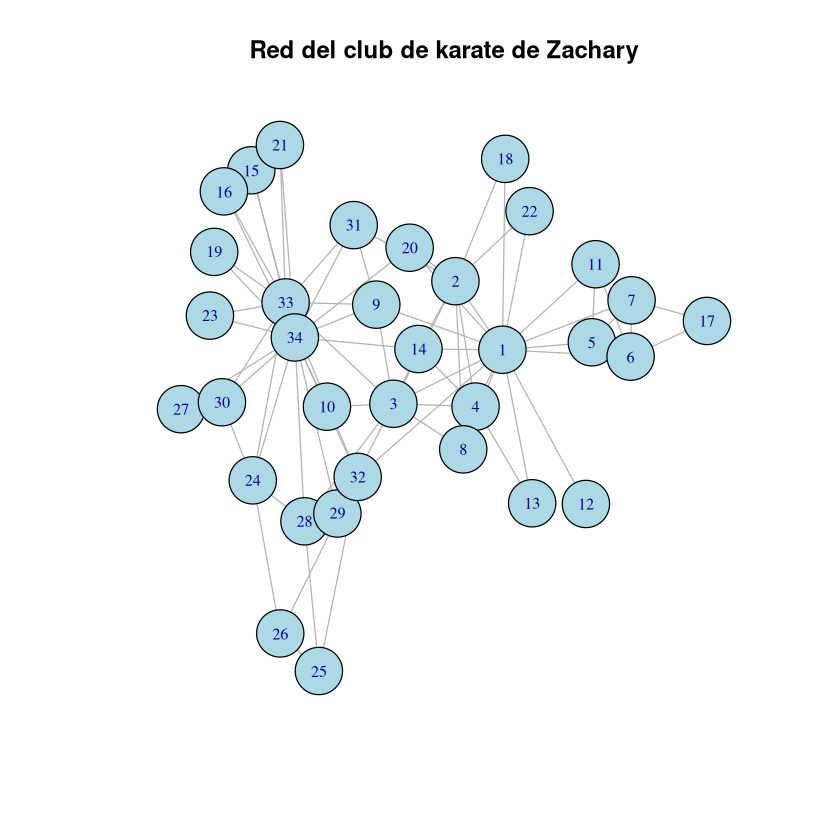

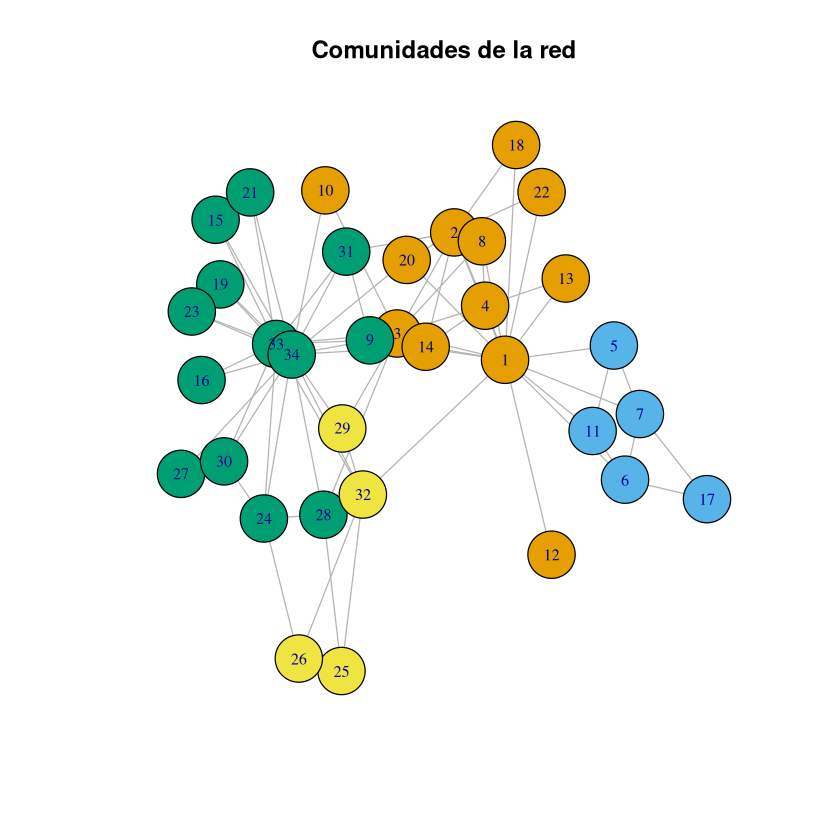

[1] 1 2 3 4

[1]  1  6 34 32

comunidad,influencer,grado
<dbl>,<int>,<dbl>
1,1,16
2,6,4
3,34,17
4,32,6


vertice,grado,sigue_conexo,numero_componentes
<int>,<dbl>,<lgl>,<dbl>
1,16,FALSE,3
2,9,TRUE,1
3,10,TRUE,1
4,6,TRUE,1
5,3,TRUE,1
6,4,TRUE,1
7,4,TRUE,1
8,4,TRUE,1
9,5,TRUE,1


,vertice,grado,sigue_conexo,numero_componentes
,<int>,<dbl>,<lgl>,<dbl>
1,1,16,FALSE,3


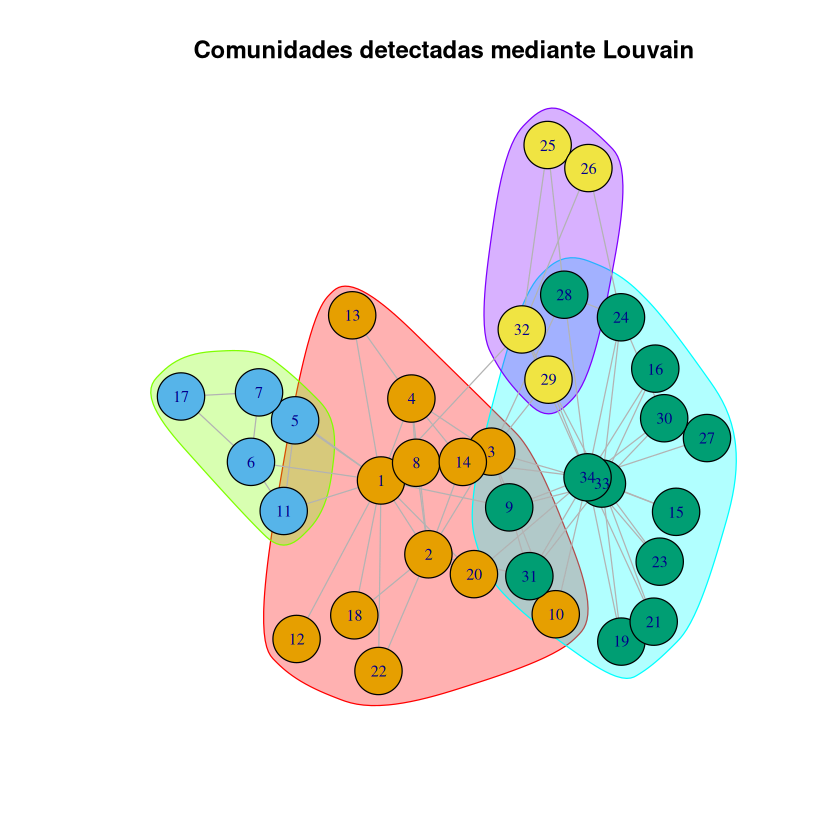

In [8]:

# 1.9. CASO PRACTICO RESUELTO: ANALISIS DE UNA RED SOCIAL ----


G_social <- make_graph("Zachary")
is_directed(G_social)

## 1.9.1. Representacion de la red----
plot(
  G_social,
  vertex.size = 18,
  vertex.color = "lightblue",
  vertex.label.cex = 0.8,
  edge.color = "grey70",
  main = "Red del club de karate de Zachary"
)

## 1.9.2. Orden y tamano de la red----
vcount(G_social)
ecount(G_social)

## 1.9.3. Conexion de la red----
is_connected(G_social)
components(G_social)$no

## 1.9.4. Grado de los vertices----
grados <- degree(G_social)
grados

vertice_mayor_grado <- which.max(grados)
vertice_mayor_grado
grados[vertice_mayor_grado]

data.frame(
  vertice = as_ids(V(G_social)),
  grado = grados
)

sort(grados, decreasing = TRUE)

## 1.9.5. Deteccion de comunidades----
comunidades <- cluster_louvain(G_social)
comunidades

length(comunidades)
sizes(comunidades)
membership(comunidades)

tabla_comunidades <- data.frame(
  vertice = as_ids(V(G_social)),
  comunidad = membership(comunidades),
  grado = grados
)

tabla_comunidades

## 1.9.6. Representacion de las comunidades----
comunidad_vertice <- membership(comunidades)

plot(
  G_social,
  vertex.color = comunidad_vertice,
  vertex.size = 18,
  vertex.label.cex = 0.8,
  edge.color = "grey70",
  main = "Comunidades de la red"
)

plot(
  comunidades,
  G_social,
  vertex.size = 18,
  vertex.label.cex = 0.8,
  edge.color = "grey70",
  main = "Comunidades detectadas mediante Louvain"
)

## 1.9.7. Vertice mas influyente de cada comunidad----
ids_comunidades <- sort(unique(membership(comunidades)))
ids_comunidades

influencers_grado <- sapply(
  ids_comunidades,
  function(i) {
    vertices_comunidad <- V(G_social)[
      membership(comunidades) == i
    ]
    grados_comunidad <- degree(
      G_social,
      v = vertices_comunidad
    )
    as_ids(
      vertices_comunidad[
        which.max(grados_comunidad)
      ]
    )
  }
)

influencers_grado

resultado_influencers <- data.frame(
  comunidad = ids_comunidades,
  influencer = influencers_grado,
  grado = grados[
    match(influencers_grado, as_ids(V(G_social)))
  ]
)

resultado_influencers

## 1.9.8. Estudio de la eliminacion de todos los vertices----
impacto_vertices <- do.call(
  rbind,
  lapply(seq_along(V(G_social)), function(v) {
    
    G_reducido <- delete_vertices(
      G_social,
      v
    )
    
    data.frame(
      vertice = v,
      grado = degree(G_social, v = v),
      sigue_conexo = is_connected(G_reducido),
      numero_componentes = components(G_reducido)$no
    )
  })
)



impacto_vertices

impacto_vertices[
  !impacto_vertices$sigue_conexo,
]

